## Beispiel an MAGNIFICA HUMANITAS, OF HIS HOLINESS, POPE LEO XIV
Deutsch: https://www.vatican.va/content/leo-xiv/de/encyclicals/documents/20260515-magnifica-humanitas.html

Englisch: https://www.vatican.va/content/leo-xiv/en/encyclicals/documents/20260515-magnifica-humanitas.html

In [1]:
import sys, os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

In [2]:
import requests
from bs4 import BeautifulSoup
import os
import re
from pprint import pprint
import json
import pandas as pd
import ast
import string
from collections import Counter
import matplotlib.pyplot as plt

import spacy
from spacy.matcher import DependencyMatcher
from spacy import displacy

from utils.tfidf_utils import calc_tf_idf, remove_punctuation
from utils.anthroscore_utils import get_scores_no_duplicates, plot_scores, grouped_stats
from utils.anthrop_search_utils import (
    flatten,
    get_lemma,
    write_matcher,
    find_verb_relations,
    find_vokativ,
    plot_semex,
    combine_results,
    normalize_verb_to_lemma,
    tokens_from_item,
    count_POS,
)

In [3]:
plots_dir = "plots/"

nlp = spacy.load('de_core_news_lg') # oder de_core_news_sm

example_path = "example_data"
try:
    os.mkdir(example_path)
    print(f"Directory '{example_path}' created successfully.")
except FileExistsError:
    print(f"Directory '{example_path}' already exists.")

Directory 'example_data' already exists.


In [4]:
url = "https://www.vatican.va/content/leo-xiv/de/encyclicals/documents/20260515-magnifica-humanitas.html"

response = requests.get(url)
response.raise_for_status()

soup = BeautifulSoup(response.content, "html.parser")

# Remove script and style elements
for tag in soup(["script", "style"]):
    tag.decompose()

text = soup.get_text(separator="\n")

# Clean up blank lines
lines = [line.strip() for line in text.splitlines() if line]
start_index = lines.index("EINLEITUNG")
lines = lines[start_index:]
end_index = lines.index("Gegeben zu Rom, bei Sankt Peter, am 15. Mai des Jahres 2026, des zweiten meines Pontifikats.")+1
lines = [re.sub(r'\[\d+\]', '', l)  for l in lines[:end_index]]
lines = [x for x in lines if x.strip()]
text = " ".join(lines).split(".")
print(f"Extracted {len(text)} text segments from the document.")
pprint(text[:5])

output_path = f"{example_path}/magnifica_humanitas.json"
with open(rf"{output_path}", 'w') as f:
    json.dump(text, f)

print(f"Saved to {output_path} ({len(lines)} lines)")


Extracted 1542 text segments from the document.
['EINLEITUNG 1',
 ' Die von Gott geschaffene grossartige Menschheit steht heute vor einer '
 'entscheidenden Wahl: Entweder sie errichtet einen neuen Turm zu Babel oder '
 'sie erbaut die Stadt, in der Gott und die Menschheit gemeinsam wohnen',
 ' Jede Generation erbt die Aufgabe, die eigene Zeit zu gestalten, damit die '
 'Geschichte zu einem Ort reifen kann, an dem die Würde jedes Menschen '
 'gewahrt, Gerechtigkeit gefördert und Geschwisterlichkeit ermöglicht wird',
 ' Doch jeder Epoche droht die Gefahr, dass die Welt unmenschlich und '
 'ungerechter wird',
 ' Wo die Menschheit riskiert, ihr wahres Gesicht zu verlieren, da erheben wir '
 'Christen unseren Blick zu dem Gott, der Mensch geworden ist, in dem Wissen, '
 'dass sich »nur im Geheimnis des fleischgewordenen Wortes das Geheimnis des '
 'Menschen wahrhaft« aufklärt']
Saved to example_data/magnifica_humanitas.json (722 lines)


In [5]:
url_en = "https://www.vatican.va/content/leo-xiv/en/encyclicals/documents/20260515-magnifica-humanitas.html"

response = requests.get(url_en)
response.raise_for_status()

soup = BeautifulSoup(response.content, "html.parser")

for tag in soup(["script", "style"]):
    tag.decompose()
text_raw_en = soup.get_text(separator="\n")

lines_eng = [line.strip() for line in text_raw_en.splitlines() if line.strip()]
# "INTRODUCTION" appears twice (TOC + body); take the last occurrence
start_index = len(lines_eng) - 1 - lines_eng[::-1].index("INTRODUCTION")
lines_eng = lines_eng[start_index:]
end_index = next(i for i, l in enumerate(lines_eng) if l.startswith("Given in Rome, at Saint Peter")) + 1
lines_en = [re.sub(r'\[\d+\]', '', l) for l in lines_eng[:end_index]]
lines_en = [x for x in lines_en if x.strip()]
text_en = " ".join(lines_en).split(".")
print(f"Extracted {len(text_en)} text segments from the English document.")

output_path_en = f"{example_path}/magnifica_humanitas_en.json"
with open(rf"{output_path_en}", 'w') as f:
    json.dump(text_en, f)

print(f"Saved to {output_path_en} ({len(lines_en)} lines)")

Extracted 1583 text segments from the English document.
Saved to example_data/magnifica_humanitas_en.json (945 lines)


## Filtering 

In [6]:
stopwords = open("config_files/spacy_stopwords.txt").read().replace("{", '[').replace("}",']')
stopwords = ast.literal_eval(stopwords)

# AI-terms
ki_terms = open("config_files/ki_terms.txt", "r").read()
ki_terms = [x for x in ki_terms.split("'") if x.strip()]
regex_ki = "".join(["\\b"+x.replace(" ","\\s")+"\\b|" for x in ki_terms])[:-1]
print(regex_ki)

ai_terms = open("config_files/ai_terms.txt", "r").read()
ai_terms = [x for x in ai_terms.split("'") if x.strip()]
regex_ai = "".join(["\\b"+x.replace(" ","\\s")+"\\b|" for x in ai_terms])[:-1]
print(regex_ai)

\bpalm\b|\blms\b|\bllama\b|\bTransformer\b|\bSprachmodelle\b|\bSprachmodell\b|\bgpt\b|\bplms\b|\bvortrainierte\sSprachmodelle\b|\bgpt-2\b|\bxlnet\b|\bgroße\sSprachmodelle\b|\bllms\b|\bgpt-3\b|\bStiftungsmodell\b|\bgpt-neo\b|\bgpt-j\b|\bchatgpt\b|\bgpt-4\b|\bKI\b|\bKünstliche\sIntelligenz\b|\bChatGPT\b|\bAI\b|\bCopilot\b|\bGemini\b|\bChatbot\b|\bLLM\b|\bChat-GPT\b|\bSprachmodell\b|\bKI-Modell\b|\bKI-System\b|\bKI-Tool\b|\bArtificial\sIntelligence\b|\bKI-Anwendung\b
\bpalm\b|\blms\b|\bllama\b|\bTransformern\b|\bLanguage\smodels\b|\bLanguage\smodel\b|\bgpt\b|\bplms\b|\bpre-trained\slanguage\smodels\b|\bgpt-2\b|\bxlnet\b|\blarge\slanguage\smodels\b|\bllms\b|\bgpt-3\b|\bFoundation\smodel\b|\bgpt-neo\b|\bgpt-j\b|\bchatgpt\b|\bgpt-4\b|\bAI\b|\bArtificial\sintelligence\b|\bChatGPT\b|\bAI\b|\bCopilot\b|\bGemini\b|\bChatbot\b|\bLLM\b|\bChat\sGPT\b|\bLanguage\smodel\b|\bAI\smodel\b|\bAI\ssystem\b|\bAI\stool\b|\bArtificial\sIntelligence\b|\bAI\sapplication\b


In [7]:
sentences_ger = [remove_punctuation(line.lower()) for line in text if re.search(regex_ki, line)]
sentences_en = [remove_punctuation(line.lower()) for line in text_en if re.search(regex_ai, line)]
print(f"Found {len(sentences_ger)} sentences in German and {len(sentences_en)} sentences in English containing KI terms.")

#save
with open(f'{example_path}/German_KI_sentences.json', 'w') as f:
    json.dump(sentences_ger, f)
with open(f"{example_path}/English_KI_sentences.json", "w") as f:
    json.dump(sentences_en, f)

pd.DataFrame({"german": pd.Series(sentences_ger), "english": pd.Series(sentences_en)}).to_csv("example_data/KI_sentences.csv", index=False)

Found 66 sentences in German and 62 sentences in English containing KI terms.


## Data Exploration

German:  66/1542 segments = 4.3% with KI terms
English: 62/1583 segments = 3.9% with AI terms


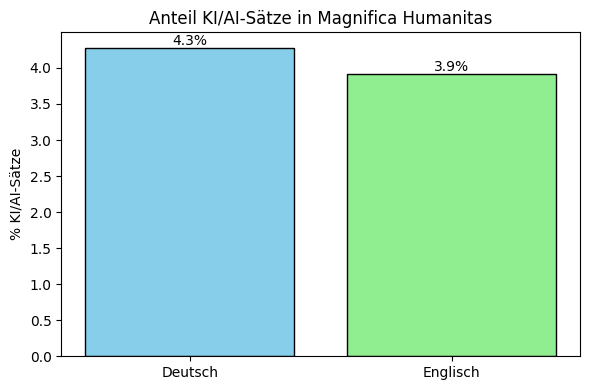

In [8]:
total_ger = len(text)
total_en = len(text_en)
ai_count_ger = len(sentences_ger)
ai_count_en = len(sentences_en)
pct_ger = 100 * ai_count_ger / total_ger
pct_en = 100 * ai_count_en / total_en

print(f"German:  {ai_count_ger}/{total_ger} segments = {pct_ger:.1f}% with KI terms")
print(f"English: {ai_count_en}/{total_en} segments = {pct_en:.1f}% with AI terms")

fig, ax = plt.subplots(figsize=(6, 4))
categories = ["Deutsch", "Englisch"]
pcts = [pct_ger, pct_en]
bars = ax.bar(categories, pcts, color=["skyblue", "lightgreen"], edgecolor="black")
for bar, val in zip(bars, pcts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() , f"{val:.1f}%", ha="center", va="bottom")
ax.set_ylabel("% KI/AI-Sätze")
ax.set_title("Anteil KI/AI-Sätze in Magnifica Humanitas")
plt.tight_layout()
plt.show()
fig.savefig(plots_dir + "pct_ai_sentences.png")

In [9]:
print("German KI sentences – top TF-IDF terms")
top_ger = calc_tf_idf(sentences_ger, stopwords_l=stopwords, top_n=20)

print("\n English AI sentences – top TF-IDF terms ")
top_en = calc_tf_idf(sentences_en, top_n=20)

German KI sentences – top TF-IDF terms
['heilige', 'demütigen treue', 'reife', 'reife bringt', 'leben reife', 'zivilisation', 'zivilisation liebe', 'unserem leben', 'heilige geist', 'geist zivilisation', 'alltags zeitalter', 'geist', 'demütigen', 'treue alltags', 'ki heilige', 'liebe', 'liebe unserem', 'treue', 'alltags', 'unserem']

 English AI sentences – top TF-IDF terms 
['love lives', 'holy', 'ai time', 'holy spirit', 'life era', 'fidelity daily', 'fidelity', 'civilization', 'brings', 'brings civilization', 'civilization love', 'humble fidelity', 'spirit', 'spirit brings', 'daily life', 'love', 'daily', 'humble', 'time holy', 'lives']


Total VERBs: 196
  bedeuten: 6
  machen: 5
  lässt: 4
  kommen: 4
  verändern: 3
  handeln: 3
  betrachten: 3
  geben: 3
  schaffen: 3
  nutzen: 3
  neigen: 3
  bestehen: 3
  erscheinen: 3
  reduzieren: 3
  verstehen: 2
  verlangen: 2
  berücksichtigen: 2
  bringen: 2
  entwerfen: 2
  erfordern: 2
  verstärken: 2
  achten: 2
  dienen: 2
  aufrufen: 2
  gehen: 2
  konzentrieren: 2
  beginnen: 2
  konzipieren: 2
  festlegen: 2
  reichen: 2
  senken: 2
  beitragen: 2
  herausforderen: 1
  erschließen: 1
  nachzeichnen: 1
  verweisen: 1
  anstellen: 1
  laufen: 1
  überholen: 1
  züchten: 1
  bauen: 1
  wachsen: 1
  ausweiten: 1
  stellen: 1
  haben: 1
  verbrauchen: 1
  einbinden: 1
  beeinflussen: 1
  einstellen: 1
  widerspiegeln: 1
  ergeben: 1
  anfangen: 1
  trainieren: 1
  anvertrauen: 1
  zeigen: 1
  beschränken: 1
  fordern: 1
  setzen: 1
  kontrollieren: 1
  nützen: 1
  bestimmen: 1
  stärken: 1
  verfügen: 1
  begleiten: 1
  prägen: 1
  entlarven: 1
  nennen: 1
  entwaffnen: 1
 

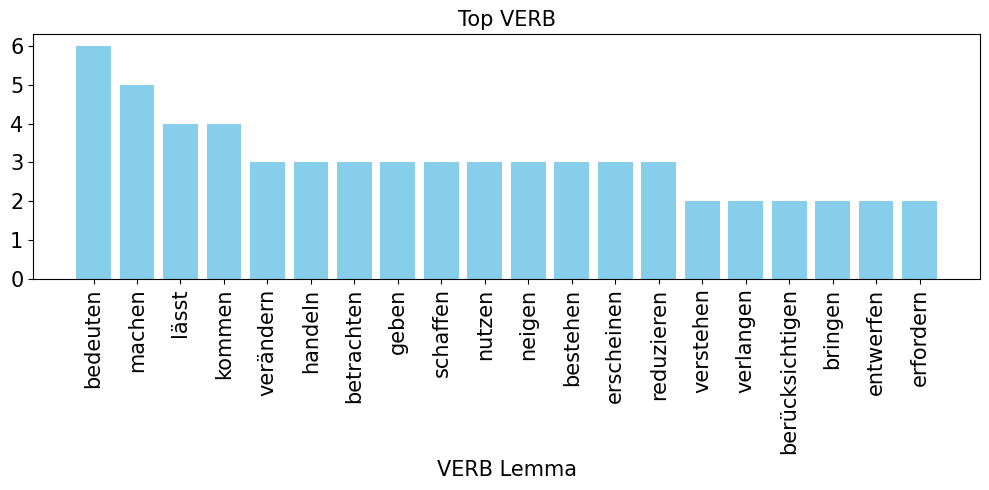

<Figure size 640x480 with 0 Axes>

In [10]:
count_POS(sentences_ger, nlp, 'VERB')

Total ADJs: 160
  künstlich: 8
  neu: 6
  digital: 6
  technologisch: 5
  menschlich: 4
  groß: 4
  wirtschaftlich: 4
  anderer: 3
  unsichtbar: 3
  bewaffnet: 3
  bestimmt: 3
  unterschiedlich: 2
  technisch: 2
  gut: 2
  streng: 2
  moralisch: 2
  öffentlich: 2
  politisch: 2
  gemeinsam: 2
  sozial: 2
  ethisch: 2
  letzter: 1
  thematisch: 1
  bewältigend: 1
  treu: 1
  unmittelbar: 1
  künftig: 1
  aufkommend: 1
  umfangreich: 1
  maßgeblich: 1
  kirchlich: 1
  beeindruckend: 1
  kurz: 1
  modern: 1
  gesagt: 1
  wertvoll: 1
  nüchtern: 1
  wachsam: 1
  aktuell: 1
  erheblich: 1
  rechter: 1
  offensichtlich: 1
  ideologisch: 1
  einfach: 1
  zwingend: 1
  konkret: 1
  verantwortungsvoll: 1
  sogenannter: 1
  eigen: 1
  klar: 1
  wirksam: 1
  epistemisch: 1
  kognitiv: 1
  zentral: 1
  technokratisch: 1
  menschenfeindlich: 1
  aufgeworfen: 1
  geduldig: 1
  posthumanistisch: 1
  allgemein: 1
  tiefgreifend: 1
  wirkungsvoll: 1
  korrekt: 1
  kritisch: 1
  perfekt: 1
  subtil: 1
 

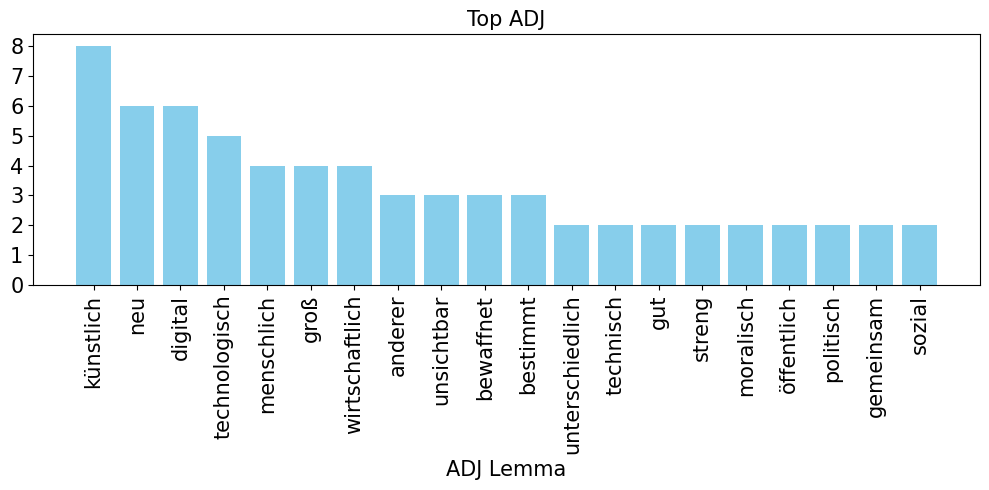

<Figure size 640x480 with 0 Axes>

In [11]:
count_POS(sentences_ger, nlp, 'ADJ')

Total PROPNs: 50
  ki: 41
  Jerusalem: 2
  Rechenkapital: 1
  Nehemia: 1
  einkaufs: 1
  Grooming: 1
  Kitools: 1
  waffensystemen: 1
  Cyberangriffe: 1


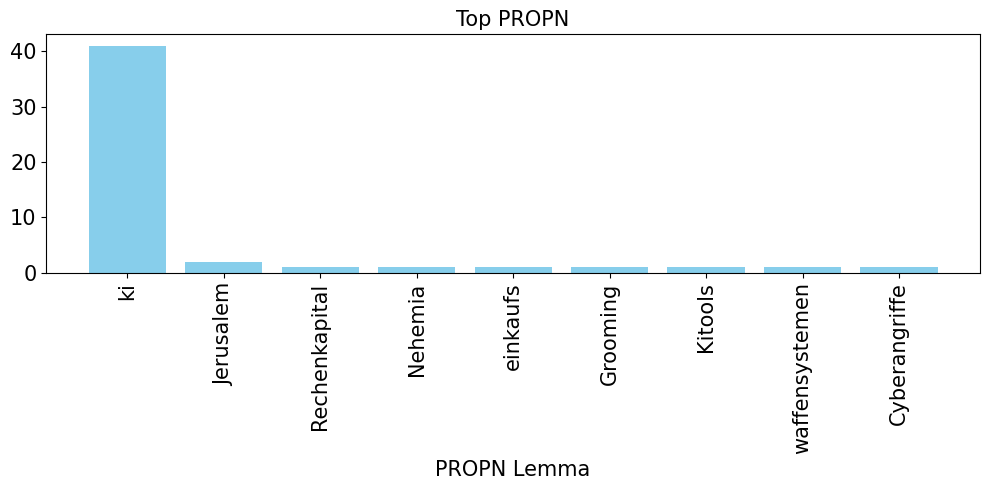

<Figure size 640x480 with 0 Axes>

In [12]:
count_POS(sentences_ger, nlp, 'PROPN')

Total NOUNs: 433
  Leben: 7
  Intelligenz: 6
  Entscheidung: 6
  daten: 5
  Auswirkung: 5
  Einsatz: 5
  Zeitalter: 5
  Welt: 4
  Technologie: 4
  Bereich: 4
  System: 4
  Zeit: 4
  Kontrolle: 4
  Mensch: 4
  Menschenwürde: 4
  Fortschritt: 4
  Robotik: 3
  Veränderung: 3
  Gefahr: 3
  Steuerung: 3
  Ressource: 3
  prozesse: 3
  kriterien: 3
  Nutzung: 3
  Schule: 3
  Arbeitnehmer: 3
  Ort: 3
  Schutz: 3
  Verteidigung: 3
  Weiterentwicklung: 2
  Plattform: 2
  Vorteil: 2
  weniger: 2
  Alltag: 2
  Möglichkeit: 2
  Entwickler: 2
  Hilfe: 2
  Umgang: 2
  Gesellschaft: 2
  Kommunikation: 2
  Kisystem: 2
  Verantwortung: 2
  Transparenz: 2
  Chance: 2
  Gemeinwohl: 2
  Verantwortlichkeit: 2
  Einführung: 2
  Menschheitsfamilie: 2
  Maschine: 2
  Ausrichtung: 2
  Macht: 2
  Grund: 2
  Wettbewerb: 2
  Frage: 2
  Thema: 2
  Anschauung: 2
  Weg: 2
  Wandel: 2
  Zusammenhang: 2
  Ebene: 2
  Organisation: 2
  Hinblick: 2
  Automatisierung: 2
  Arbeit: 2
  Aufgabe: 2
  Maßnahme: 2
  Wirtschaft: 

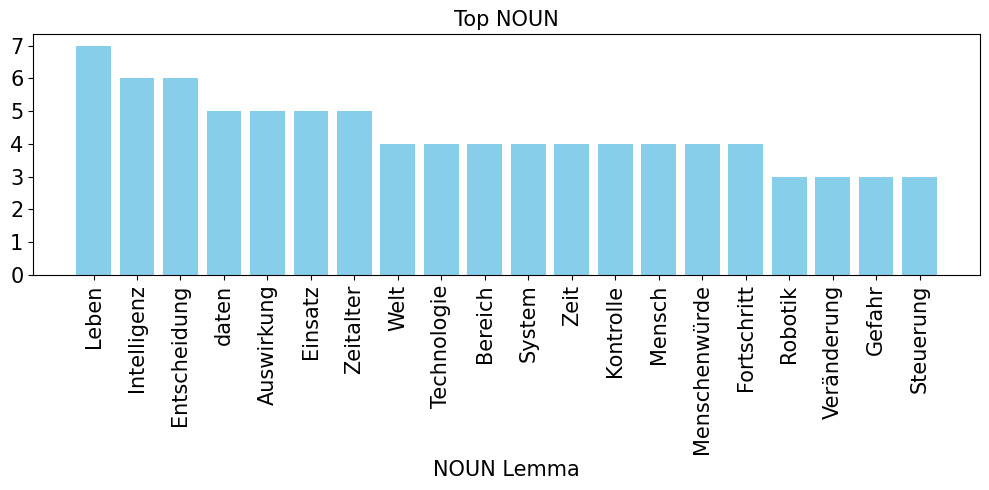

<Figure size 640x480 with 0 Axes>

In [13]:
count_POS(sentences_ger, nlp, 'NOUN')

## AnthroScore 

In [14]:
# generate input string for AnthroScore for both languages
terminal_input_eng = f'''python3 anthroscore/src/get_anthroscore.py --input_file example_data/KI_sentences.csv--text_column_name english --entities {ai_terms} --output_file example_data/eng_scores.csv --text_id_name id '''
terminal_input_eng

"python3 anthroscore/src/get_anthroscore.py --input_file example_data/KI_sentences.csv--text_column_name english --entities ['palm', 'lms', 'llama', 'Transformern', 'Language models', 'Language model', 'gpt', 'plms', 'pre-trained language models', 'gpt-2', 'xlnet', 'large language models', 'llms', 'gpt-3', 'Foundation model', 'gpt-neo', 'gpt-j', 'chatgpt', 'gpt-4', 'AI', 'Artificial intelligence', 'ChatGPT', 'AI', 'Copilot', 'Gemini', 'Chatbot', 'LLM', 'Chat GPT', 'Language model', 'AI model', 'AI system', 'AI tool', 'Artificial Intelligence', 'AI application'] --output_file example_data/eng_scores.csv --text_id_name id "

In [15]:
# generate input string for AnthroScore for both languages
terminal_input_ger= f'''python3 anthroscore/src/get_anthroscore.py --input_file example_data/KI_sentences.json --text_column_name german --entities {ki_terms} --output_file example_data/ger_scores.csv --text_id_name id '''
terminal_input_ger

"python3 anthroscore/src/get_anthroscore.py --input_file example_data/KI_sentences.json --text_column_name german --entities ['palm', 'lms', 'llama', 'Transformer', 'Sprachmodelle', 'Sprachmodell', 'gpt', 'plms', 'vortrainierte Sprachmodelle', 'gpt-2', 'xlnet', 'große Sprachmodelle', 'llms', 'gpt-3', 'Stiftungsmodell', 'gpt-neo', 'gpt-j', 'chatgpt', 'gpt-4', 'KI', 'Künstliche Intelligenz', 'ChatGPT', 'AI', 'Copilot', 'Gemini', 'Chatbot', 'LLM', 'Chat-GPT', 'Sprachmodell', 'KI-Modell', 'KI-System', 'KI-Tool', 'Artificial Intelligence', 'KI-Anwendung'] --output_file example_data/ger_scores.csv --text_id_name id "

In [16]:
try:
    df_eng = get_scores_no_duplicates("example_data/eng_scores.csv")
    df_ger = get_scores_no_duplicates("example_data/ger_scores.csv")
    plot_scores(df_eng, df_ger, "Magnifica Humanitas AnthroScore")
    grouped_stats(pd.concat([df_eng, df_ger]), "grouped_stats_magnifica_humanitas.png")
except FileNotFoundError as e:
    print(f"AnthroScore results not found ({e}).")
    print("Run the AnthroScore pipeline first:\n  ", terminal_input_eng, "\n  ", terminal_input_ger)

AnthroScore results not found ([Errno 2] No such file or directory: 'example_data/eng_scores.csv').
Run the AnthroScore pipeline first:
   python3 anthroscore/src/get_anthroscore.py --input_file example_data/KI_sentences.csv--text_column_name english --entities ['palm', 'lms', 'llama', 'Transformern', 'Language models', 'Language model', 'gpt', 'plms', 'pre-trained language models', 'gpt-2', 'xlnet', 'large language models', 'llms', 'gpt-3', 'Foundation model', 'gpt-neo', 'gpt-j', 'chatgpt', 'gpt-4', 'AI', 'Artificial intelligence', 'ChatGPT', 'AI', 'Copilot', 'Gemini', 'Chatbot', 'LLM', 'Chat GPT', 'Language model', 'AI model', 'AI system', 'AI tool', 'Artificial Intelligence', 'AI application'] --output_file example_data/eng_scores.csv --text_id_name id  
   python3 anthroscore/src/get_anthroscore.py --input_file example_data/KI_sentences.json --text_column_name german --entities ['palm', 'lms', 'llama', 'Transformer', 'Sprachmodelle', 'Sprachmodell', 'gpt', 'plms', 'vortrainierte Sp

## RegEx and SemEx

In [17]:
# import generated_data/cognitive_v_lexicon.xlsx
cognitive_v_lexicon = pd.read_excel("config_files/cognitive_v_lexicon.xlsx")
#cognitive_v_lexicon.head()

In [18]:
# choose and build lexicon/regex for anthropomorphic verbs
base_verbs = cognitive_v_lexicon['Unnamed: 0'].tolist()
synonyms_all = []
for syn_str in cognitive_v_lexicon['synonyms']:
    synonyms_all.extend(ast.literal_eval(syn_str))

verb_synonyms = [x.lower().strip() for x in base_verbs + synonyms_all]
print(f"found {len(verb_synonyms)} verb synonyms:", verb_synonyms)
anthro_regex = "".join(["\\b"+x.replace(" ","\\s")+"\\b|" for x in verb_synonyms])[:-1]
print(anthro_regex)
print("------------------")

# compute verb lemmas for dependency matching
verb_lemmas = flatten([get_lemma(v, nlp) for v in verb_synonyms])

# run SemEx on German encyclical KI sentences
anthro_ger_dep_sb = {}
anthro_ger_dep_ob = {}
anthro_ger_dep_v = {}

for i, sent in enumerate(sentences_ger):
    doc = nlp(sent)
    relations_sb, relations_ob = find_verb_relations(doc, verb_lemmas)
    if relations_sb:
        anthro_ger_dep_sb[str(i)] = relations_sb
    if relations_ob:
        anthro_ger_dep_ob[str(i)] = relations_ob
    relations_v = find_vokativ(doc)
    if relations_v:
        anthro_ger_dep_v[str(i)] = relations_v

anthro_ger_dep = {"sb": anthro_ger_dep_sb, "ob": anthro_ger_dep_ob, "v": anthro_ger_dep_v}
print(f"Subject relations: {len(anthro_ger_dep_sb)}, Percentage: {100*len(anthro_ger_dep_sb)/len(sentences_ger):.1f}%")
print(f"Object relations:  {len(anthro_ger_dep_ob)}, Percentage: {100*len(anthro_ger_dep_ob)/len(sentences_ger):.1f}%")
print(f"Vocative:          {len(anthro_ger_dep_v)}, Percentage: {100*len(anthro_ger_dep_v)/len(sentences_ger):.1f}%")
print(f"All relations: {sum(len(v) for v in anthro_ger_dep.values())}")

found 75 verb synonyms: ['kennen', 'denken', 'glauben', 'verstehen', 'erinnern', 'vergessen', 'raten', 'vorgeben', 'träumen', 'meinen', 'vermuten', 'behaupten', 'fühlen', 'annehmen', 'auskennen', 'bekannt sein', 'befreundet sein', 'meinen', 'denken', 'vermuten', 'annehmen', 'vertrauen', 'einfallen', 'entsinnen', 'wiedererkennen', 'empfehlen', 'nahelegen', 'vorschlagen', 'zureden', 'aufdecken', 'auflösen', 'enträtseln', 'knacken', 'lösen', 'herausbekommen', 'herauskriegen', 'phantasieren', 'pennen', 'ratzen', 'schlafen', 'schlummern', 'glauben', 'sagen', 'bedeuten', 'bezeichnen', 'annehmen', 'assumieren', 'glauben', 'konjizieren', 'meinen', 'präsumieren', 'supponieren', 'beteuern', 'versichern', 'durchsetzen', 'abtasten', 'berühren', 'betasten', 'erspüren', 'ertasten', 'spüren', 'tasten', 'verspüren', 'empfinden', 'vermuten', 'unterstellen', 'glauben', 'spekulieren', 'denken', 'entgegennehmen', 'in empfang nehmen', 'empfangen', 'akzeptieren', 'sich kümmern', 'sich widmen']
\bkennen\b|\b

Subject relations: 6, Percentage: 9.1%
Object relations:  7, Percentage: 10.6%
Vocative:          0, Percentage: 0.0%
All relations: 13


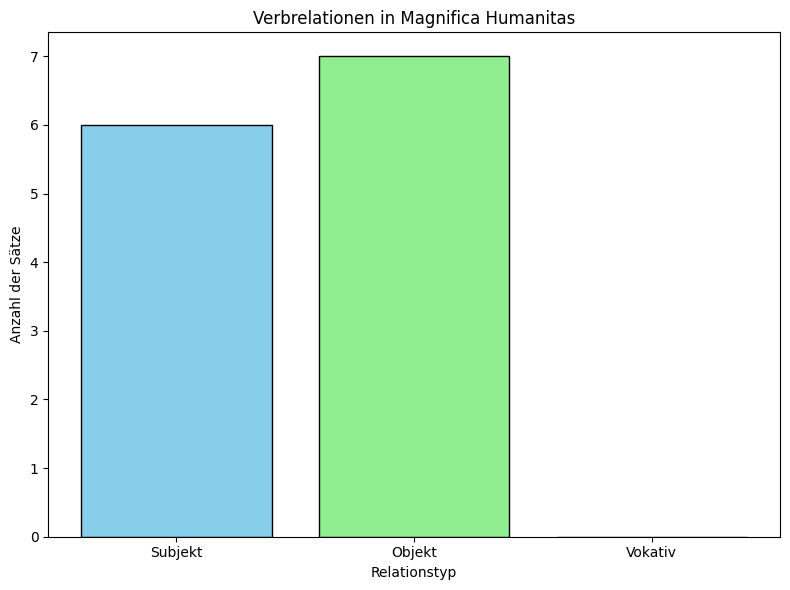

<Figure size 640x480 with 0 Axes>

In [19]:
plot_semex(anthro_ger_dep, "Magnifica Humanitas", "Verbrelationen in", plots_dir=plots_dir)

In [20]:
df_sb = pd.DataFrame.from_dict(anthro_ger_dep_sb, orient='index')
df_ob = pd.DataFrame.from_dict(anthro_ger_dep_ob, orient='index')
df_v = pd.DataFrame.from_dict(anthro_ger_dep_v, orient='index')
df_out = pd.concat([df_sb, df_ob, df_v], ignore_index=True)
df_out.to_csv(f"{example_path}/anthro_ger_dep.csv", index=False)
print(df_out.shape)

(13, 2)


In [21]:
for label, cat_dict in [("SUBJECT", anthro_ger_dep_sb), ("OBJECT", anthro_ger_dep_ob), ("VOCATIVE", anthro_ger_dep_v)]:
    print(f"\n{'-'*60}")
    print(f"  {label} ({len(cat_dict)} sentences)")
    print(f"{'-'*60}")
    for idx, relations in cat_dict.items():
        print(f"\n[{idx}] {sentences_ger[int(idx)]}")
        for x in relations:
            print(f"type: {x['type']}, verb: {x['verb']}, dependent: {x['dependent']}, dep_label: {x['dep_label']}, dep_pos: {x['dep_pos']}")



------------------------------------------------------------
  SUBJECT (6 sentences)
------------------------------------------------------------

[18]  wenn man zur vorsicht zu strengen kontrollen und manchmal auch zu einer verlangsamung bei der einführung der ki aufruft bedeutet das nicht gegen den fortschritt zu sein sondern eine verantwortungsvolle sorge um die menschheitsfamilie zu zeigen
type: verb_subject, verb: bedeutet, dependent: man, dep_label: sb, dep_pos: PRON
type: verb_subject, verb: bedeutet, dependent: das, dep_label: sb, dep_pos: PRON

[24]  in einer welt in der wenige akteure daten rechenkapital und regulierungsmacht konzentrieren bedeutet das sprechen vom gemeinwohl diese neue epistemische wirtschaftliche und politische asymmetrie zu entlarven und die neuen monopole von ki beim namen zu nennen
type: verb_subject, verb: bedeutet, dependent: sprechen, dep_label: sb, dep_pos: NOUN

[25]  ki zu entwaffnen bedeutet sie der logik des bewaffneten wettbewerbs zu entziehen 

## Run through models MetaphorBERT and SentenceMetaphorBERT

In [22]:
from Metaphor_model.model import load_metaphor_bert, predict_sentences as metaphor_predict

METAPHOR_WEIGHTS = "Metaphor_model/metaphor_bert_best.pt"
DOMAIN_CKPT_DIR  = "Metaphor_model/results"

non_ai_ger = [remove_punctuation(s.lower()) for s in text if not re.search(regex_ki, s) and len(s.strip()) > 10]
print(f"AI sentences: {len(sentences_ger)} | Non-AI sentences: {len(non_ai_ger)}")

try:
    metaphor_model_bert, metaphor_tokenizer, domain_names = load_metaphor_bert(
        metaphor_weights=METAPHOR_WEIGHTS,
        domain_ckpt_dir=DOMAIN_CKPT_DIR,
    )
    print(f"MetaphorBERT loaded — domains: {domain_names}")

    metaphor_results_ai    = metaphor_predict(sentences_ger, metaphor_model_bert, metaphor_tokenizer, domain_names, nlp)
    metaphor_results_nonai = metaphor_predict(non_ai_ger,    metaphor_model_bert, metaphor_tokenizer, domain_names, nlp)

    metaphor_results_ai["group"]    = "AI"
    metaphor_results_nonai["group"] = "non-AI"

    metaphor_results_all = pd.concat([metaphor_results_ai, metaphor_results_nonai], ignore_index=True)
    metaphor_results_all.to_csv("example_data/metaphor_results_ger.csv", index=False)

    for grp, df in [("AI", metaphor_results_ai), ("non-AI", metaphor_results_nonai)]:
        n_meta = (df["prediction"] == 1).sum()
        print(f"{grp}: {n_meta}/{len(df)} metaphorical tokens ({100*n_meta/len(df):.1f}%)")

except FileNotFoundError as e:
    metaphor_model_bert    = None
    metaphor_results_ai    = None
    metaphor_results_nonai = None
    metaphor_results_all   = None
    print(f"MetaphorBERT not ready: {e}")
    print("Run notebooks/metaphors.ipynb to train and save the model first.")

AI sentences: 66 | Non-AI sentences: 1285


The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


MetaphorBERT not ready: No checkpoint found for domain 'arzt' in Metaphor_model/results/arzt. Run metaphors.ipynb to train domain models first.
Run notebooks/metaphors.ipynb to train and save the model first.


In [ ]:
from Metaphor_model.sentence_model import load_sentence_metaphor_bert, predict_sentence_metaphor

SENT_BERT_DIR = "Metaphor_model/sentence_bert_results/best"

try:
    sent_model, sent_tokenizer = load_sentence_metaphor_bert(SENT_BERT_DIR)
    print(f"SentenceMetaphorBERT loaded from {SENT_BERT_DIR}")

    sent_results_ai    = predict_sentence_metaphor(sentences_ger, sent_model, sent_tokenizer)
    sent_results_nonai = predict_sentence_metaphor(non_ai_ger,    sent_model, sent_tokenizer)

    sent_results_ai["group"]    = "AI"
    sent_results_nonai["group"] = "non-AI"
    sent_results_all = pd.concat([sent_results_ai, sent_results_nonai], ignore_index=True)
    sent_results_all.to_csv("example_data/sentence_metaphor_results_ger.csv", index=False)

    rate_ai_sent    = sent_results_ai["prediction"].mean()
    rate_nonai_sent = sent_results_nonai["prediction"].mean()
    print(f"SentenceMetaphorBERT — AI: {rate_ai_sent:.1%} | non-AI: {rate_nonai_sent:.1%}")

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(["AI", "non-AI"], [rate_ai_sent, rate_nonai_sent],
           color=["steelblue", "darkorange"], edgecolor="black")
    ax.set_title("SentenceMetaphorBERT — Anteil metaphorischer Sätze")
    ax.set_ylabel("Anteil")
    ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.show()
    fig.savefig(plots_dir + "sentence_metaphorbert_ai_vs_nonai.png")
    print("Saved plots/sentence_metaphorbert_ai_vs_nonai.png")

except FileNotFoundError as e:
    sent_model         = None
    sent_results_ai    = None
    sent_results_nonai = None
    sent_results_all   = None
    print(f"SentenceMetaphorBERT not ready: {e}")
    print("Call train_sentence_metaphor_model() in notebooks/metaphors.ipynb to train first.")

## Use BasicBERT on english encyclical

In [24]:
# BasicBERT is not yet implemented (BasicBERT/ is empty).
# MetaphorBERT uses bert-base-german-cased — cannot be applied to English.
# Placeholder for when a BasicBERT English model is available:
#
#   from BasicBERT.model import load_basic_bert
#   non_ai_en = [remove_punctuation(s.lower()) for s in text_en if not re.search(regex_ai, s) and len(s.strip()) > 10]
#   basic_model, basic_tokenizer = load_basic_bert("BasicBERT/basic_bert_best.pt")
#   basic_results_ai    = basic_model.predict(sentences_en)
#   basic_results_nonai = basic_model.predict(non_ai_en)
#   fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
#   for ax, preds, title in zip(axes, [basic_results_ai, basic_results_nonai],
#                                ["EN AI sentences", "EN non-AI sentences"]):
#       pd.Series(preds).value_counts().plot(kind="bar", ax=ax, color="skyblue", edgecolor="black")
#       ax.set_title(title); ax.set_xlabel("Predicted label"); ax.set_ylabel("Count")
#   plt.suptitle("BasicBERT — English encyclical"); plt.tight_layout(); plt.show()
#   fig.savefig(plots_dir + "basicbert_en_predictions.png")
print("BasicBERT not yet implemented — add model to BasicBERT/ to enable.")

BasicBERT not yet implemented — add model to BasicBERT/ to enable.


In [25]:
# Compare MetaphorBERT results: AI vs non-AI German sentences
if metaphor_results_ai is not None:
    rate_ai    = (metaphor_results_ai["prediction"]    == 1).mean()
    rate_nonai = (metaphor_results_nonai["prediction"] == 1).mean()
    print(f"Metaphor rate — AI: {rate_ai:.1%}  |  non-AI: {rate_nonai:.1%}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Left: overall metaphor rate comparison
    axes[0].bar(["AI", "non-AI"], [rate_ai, rate_nonai],
                color=["steelblue", "darkorange"], edgecolor="black")
    axes[0].set_title("MetaphorBERT — Anteil metaphorischer Token", fontsize=13)
    axes[0].set_ylabel("Anteil")
    axes[0].set_ylim(0, 1)

    # Right: dominant-domain breakdown for AI sentences
    if "dominant_domain" in metaphor_results_ai.columns:
        domain_counts = (
            metaphor_results_ai[metaphor_results_ai["prediction"] == 1]["dominant_domain"]
            .value_counts()
        )
        domain_counts.plot(kind="bar", ax=axes[1], color="skyblue", edgecolor="black")
        axes[1].set_title("Dominante Domain (AI-Sätze, metaphorisch)", fontsize=13)
        axes[1].set_xlabel("Domain")
        axes[1].set_ylabel("Anzahl Token")
        axes[1].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()
    fig.savefig(plots_dir + "metaphorbert_ai_vs_nonai.png")
    print("Saved plots/metaphorbert_ai_vs_nonai.png")
else:
    print("Run MetaphorBERT cell above first.")

Run MetaphorBERT cell above first.
